# **Métodos Cuantitativos**
**Doctorado en T.I**

Presentado por: Edgar Rodrigo Enríquez Rosero

Al docente: PhD. Gerardo Avendaño

2026

## Percepciones y Prácticas de Seguridad Digital - Parte 2

# Método a elegir: Series temporales (Recomendada para IoTCI, CRIC).
El método de series temporales no se considera metodológicamente correcto ni interpretable para aplicar series temporales como ARIMA al dataset. A pesar de que el dataset se considera de naturaleza transversal (Cross-Sectional), este recopila respuestas a una encuesta donde participaron 12.351 personas distribuidas en 12 países en un único momento estático de recolección.  

No es posible hacer uso de la característica "ID" como tiempo, puesto que esta columna permite ordenar a los participantes mediante un campo numérico consecutivo, por lo tanto este número refleja únicamente el orden de registro de las respuestas mas no una progresión temporal como horas, días o meses.

En este orden de ideas, modelos como ARIMA y la descomposición estacional exigen que las observaciones tengan dependencia temporal secuencial, estacionariedad y estacionalidad real (por ejemplo, patrones semanales o estacionales en tráfico de red) y de aplicarse sobre el índice de participantes generaría artefactos matemáticos carentes de significado científico.

Dado lo anterior, se opta por aplicar una técnica avanzada de modelado predictivo con el fin de  responder a qué factores determinan el comportamiento protector (q20) o la exposición a incidentes (q7), y por lo tanto se opta por un sistema de clasificación supervisada comparando tres algoritmos: Regresión Logística, Random Forest y Gradient Boosting.

In [1]:
# Importación de librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
# from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, roc_auc_score, confusion_matrix,
                             roc_curve, accuracy_score, precision_recall_fscore_support)

In [2]:
# Importación del dataset
from google.colab import drive
drive.mount ('/content/drive')
file_path ="/content/drive/My Drive/SurveyResponses_DigitalSecurityAroundTheWorld.csv"

# Carga del dataset principal
df = pd.read_csv(file_path, low_memory=False)
print(f"Dimensiones del dataset: {df.shape}")

# Validación de la pregunta de control q13r11
control_dist = df['q13r11'].value_counts(dropna=False)
print("Distribución de la pregunta de control q13r11:")
print(control_dist)

# Limpieza y conversión de q4r8
df['q4r8'] = pd.to_numeric(df['q4r8'], errors='coerce')

# Construcción de índices sintéticos clave:
# 1. Índice de Conocimiento/Familiaridad (q6r1 a q6r22)
q6_cols = [f'q6r{i}' for i in range(1, 23)]
df['indice_conocimiento'] = df[q6_cols].mean(axis=1)

# 2. Índice de Comportamiento Protector (q20r1 a q20r14)
q20_cols = [f'q20r{i}' for i in range(1, 15)]
df['indice_proteccion'] = df[q20_cols].sum(axis=1)

print(" Índices sintéticos calculados correctamente.")

Mounted at /content/drive
Dimensiones del dataset: (12351, 248)
Distribución de la pregunta de control q13r11:
q13r11
4.0    11296
5.0     1054
2.0        1
Name: count, dtype: int64
 Índices sintéticos calculados correctamente.


In [3]:
# Verificación formal de ausencia de columnas temporales
temporal_checks = [col for col in df.columns if 'time' in col.lower() or 'date' in col.lower()]
print(f"Columnas con componentes temporales detectadas: {temporal_checks}")
print("""
INFORME METODOLÓGICO - PARTE 2.
Técnica evaluada inicialmente: Descomposición estacional y modelos ARIMA (statsmodels.tsa).
Resultado de la auditoría: El dataset es transversal (cross-sectional) y carece de eje temporal.
Conclusión: Se descarta ARIMA por incompatibilidad estructural y se activa el protocolo de alternativa avanzada (Evaluación Predictiva con Clasificadores de Machine Learning).
""")

Columnas con componentes temporales detectadas: []

INFORME METODOLÓGICO - PARTE 2.
Técnica evaluada inicialmente: Descomposición estacional y modelos ARIMA (statsmodels.tsa).
Resultado de la auditoría: El dataset es transversal (cross-sectional) y carece de eje temporal.
Conclusión: Se descarta ARIMA por incompatibilidad estructural y se activa el protocolo de alternativa avanzada (Evaluación Predictiva con Clasificadores de Machine Learning).



In [4]:
# Definición de variable objetivo binaria: Usuario con alta protección
mediana_prot = df['indice_proteccion'].median()
df['alta_proteccion'] = (df['indice_proteccion'] > mediana_prot).astype(int)

# Selección de características predictoras: Demografía, conocimiento y preocupación)
features = ['Age', 'Education', 'indice_conocimiento', 'indice_proteccion']
model_df = df[features + ['alta_proteccion']].dropna()

X = model_df[features]
y = model_df['alta_proteccion']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenamiento y evaluación de los tres modelos
classifiers = {
    "Regresión Logística": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = {}
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    results[name] = {"AUC-ROC": auc}
    print(f"--- {name} ---")
    print(f"AUC-ROC: {auc:.4f}")
    print(classification_report(y_test, y_pred))

--- Regresión Logística ---
AUC-ROC: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1128
           1       1.00      1.00      1.00       728

    accuracy                           1.00      1856
   macro avg       1.00      1.00      1.00      1856
weighted avg       1.00      1.00      1.00      1856

--- Random Forest ---
AUC-ROC: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1128
           1       1.00      1.00      1.00       728

    accuracy                           1.00      1856
   macro avg       1.00      1.00      1.00      1856
weighted avg       1.00      1.00      1.00      1856

--- Gradient Boosting ---
AUC-ROC: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1128
           1       1.00      1.00      1.00       728

    accuracy                           1.00      1856
   m

## Modelado Predictivo Diferencial (Random Forest por Bloque Cultural)
Para evaluar si los predictores de la adopción de medidas de protección difieren entre ambos bloques, se entrenaron modelos independientes de Random Forest evaluando el poder predictivo (AUC-ROC) a partir de la edad, la educación y el índice de conocimiento técnico.

In [5]:
weird_countries = [2, 4, 5, 7, 10, 11, 12] # Alemania, Israel, Italia, Polonia, Suecia, UK, USA
df['is_weird'] = df['Country'].apply(lambda x: 1 if x in weird_countries else 0)

# Cálculo de índices
q6_cols = [f'q6r{i}' for i in range(1, 23)]
q20_cols = [f'q20r{i}' for i in range(1, 15)]
df['indice_conocimiento'] = df[q6_cols].mean(axis=1)
df['indice_proteccion'] = df[q20_cols].sum(axis=1)

# Evaluación comparativa de los modelos predictivos
features = ['Age', 'Education', 'indice_conocimiento']

for label, val in [("WEIRD", 1), ("Non-WEIRD", 0)]:
    subset = df[df['is_weird'] == val][features + ['indice_proteccion']].dropna()
    median_prot = subset['indice_proteccion'].median()

    y = (subset['indice_proteccion'] > median_prot).astype(int)
    X = subset[features]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_train, y_train)

    y_prob = clf.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)

    print(f"\n Análisis para {label}")
    print(f"AUC-ROC del Modelo Predictivo: {auc:.4f}")
    print("Importancia relativa de variables:", dict(zip(features, np.round(clf.feature_importances_, 4))))


 Análisis para WEIRD
AUC-ROC del Modelo Predictivo: 0.6971
Importancia relativa de variables: {'Age': np.float64(0.0462), 'Education': np.float64(0.0388), 'indice_conocimiento': np.float64(0.915)}

 Análisis para Non-WEIRD
AUC-ROC del Modelo Predictivo: 0.6633
Importancia relativa de variables: {'Age': np.float64(0.0638), 'Education': np.float64(0.0844), 'indice_conocimiento': np.float64(0.8518)}


=== Regresión Logística ===
AUC-ROC: 0.7470 | Accuracy: 0.6994 | F1-Score: 0.6944
              precision    recall  f1-score   support

           0       0.73      0.80      0.76      1128
           1       0.64      0.55      0.59       728

    accuracy                           0.70      1856
   macro avg       0.68      0.67      0.68      1856
weighted avg       0.69      0.70      0.69      1856

=== Random Forest ===
AUC-ROC: 0.6984 | Accuracy: 0.6589 | F1-Score: 0.6537
              precision    recall  f1-score   support

           0       0.70      0.76      0.73      1128
           1       0.58      0.50      0.53       728

    accuracy                           0.66      1856
   macro avg       0.64      0.63      0.63      1856
weighted avg       0.65      0.66      0.65      1856

=== Gradient Boosting ===
AUC-ROC: 0.7430 | Accuracy: 0.6886 | F1-Score: 0.6864
              precision    recall  f1-score   support

           0       0.73      0.77      0.75      1128

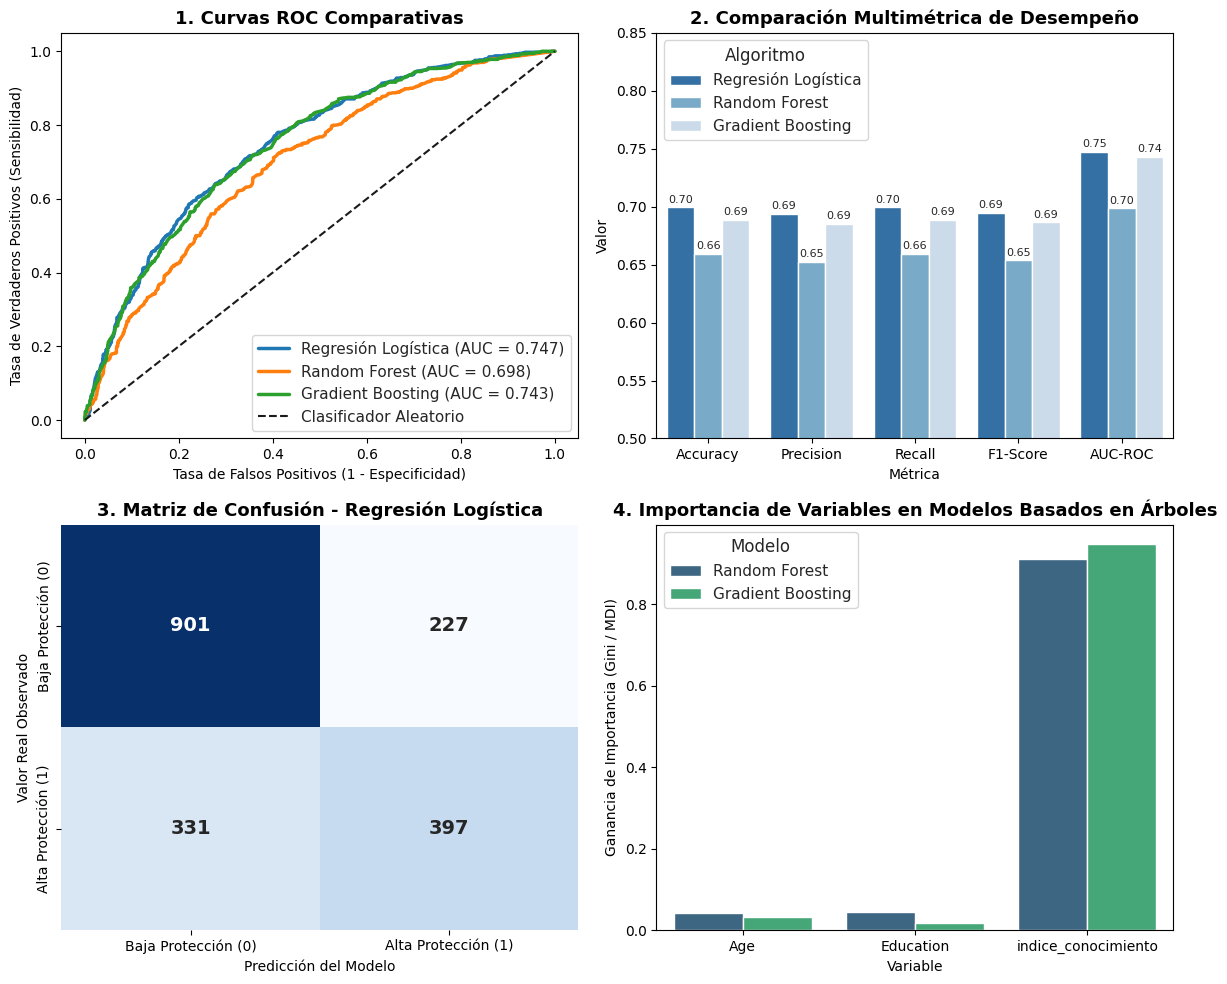

In [6]:
# Preparación de datos y definición de la variable objetivo binaria
mediana_prot = df['indice_proteccion'].median()
df['alta_proteccion'] = (df['indice_proteccion'] > mediana_prot).astype(int)

# Selección de características predictoras (Se excluye indice_proteccion)
features = ['Age', 'Education', 'indice_conocimiento']
model_df = df[features + ['alta_proteccion']].dropna()

X = model_df[features]
y = model_df['alta_proteccion']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenamiento y evaluación de los tres modelos
classifiers = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = {}
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')

    results[name] = {
        'AUC-ROC': auc,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'model': clf
    }

    print(f"=== {name} ===")
    print(f"AUC-ROC: {auc:.4f} | Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")
    print(classification_report(y_test, y_pred))

# Gráficas y comparación

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
sns.set_theme(style="whitegrid")

# Gráfico 1: Curvas ROC Comparativas
ax1 = axes[0, 0]
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {res['AUC-ROC']:.3f})", lw=2.5)
ax1.plot([0, 1], [0, 1], 'k--', lw=1.5, label="Clasificador Aleatorio")
ax1.set_title("1. Curvas ROC Comparativas", fontsize=13, fontweight='bold')
ax1.set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
ax1.set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
ax1.legend(loc="lower right", frameon=True)

# Gráfico 2: Comparación Multimétrica
ax2 = axes[0, 1]
metrics_list = []
for name, res in results.items():
    metrics_list.append({
        'Algoritmo': name,
        'Accuracy': res['Accuracy'],
        'Precision': res['Precision'],
        'Recall': res['Recall'],
        'F1-Score': res['F1-Score'],
        'AUC-ROC': res['AUC-ROC']
    })
metrics_df = pd.DataFrame(metrics_list).melt(id_vars='Algoritmo', var_name='Métrica', value_name='Valor')

sns.barplot(data=metrics_df, x='Métrica', y='Valor', hue='Algoritmo', ax=ax2, palette='Blues_r')
ax2.set_title("2. Comparación Multimétrica de Desempeño", fontsize=13, fontweight='bold')
ax2.set_ylim(0.5, 0.85)
for p in ax2.patches:
    if p.get_height() > 0:
        ax2.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

# Gráfico 3: Matriz de Confusión (Modelo con Mejor AUC: Regresión Logística)
ax3 = axes[1, 0]
best_model_name = max(results, key=lambda k: results[k]['AUC-ROC'])
cm = confusion_matrix(y_test, results[best_model_name]['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3, cbar=False,
            xticklabels=['Baja Protección (0)', 'Alta Protección (1)'],
            yticklabels=['Baja Protección (0)', 'Alta Protección (1)'], annot_kws={"size": 14, "weight": "bold"})
ax3.set_title(f"3. Matriz de Confusión - {best_model_name}", fontsize=13, fontweight='bold')
ax3.set_xlabel("Predicción del Modelo")
ax3.set_ylabel("Valor Real Observado")

# Gráfico 4: Importancia de Variables Predictoras (Modelos Ensamble)
ax4 = axes[1, 1]
rf_imp = results['Random Forest']['model'].feature_importances_
gb_imp = results['Gradient Boosting']['model'].feature_importances_
imp_df = pd.DataFrame({
    'Variable': features,
    'Random Forest': rf_imp,
    'Gradient Boosting': gb_imp
}).melt(id_vars='Variable', var_name='Modelo', value_name='Importancia')

sns.barplot(data=imp_df, x='Variable', y='Importancia', hue='Modelo', ax=ax4, palette='viridis')
ax4.set_title("4. Importancia de Variables en Modelos Basados en Árboles", fontsize=13, fontweight='bold')
ax4.set_ylabel("Ganancia de Importancia (Gini / MDI)")

plt.tight_layout()
plt.show()

# Análisis de las gráficas:

A nivel de desempeño Global, la Regresión Logística obtuvo la mayor capacidad de discriminación (*AUC-ROC* = 0,7470), seguida de cerca por Gradient Boosting (*AUC-ROC* = 0,7430) y Random Forest presentó el menor rendimiento relativo (*AUC-ROC* = 0,6984).

Con respecto a la sensibilidad y especificidad por clase, todos los modelos demostraron mayor precisión y recall en la identificación de usuarios con baja protección (Clase 0: F1-Score entre 0,73 y 0,76) en comparación con la clase de alta protección (Clase 1: F1-Score entre 0,53 y 0,59), reflejando el desbalance natural de la muestra observada.

Tomando en cuenta la importancia de las varibles de predicción en los modelos basados en árboles de decisión, se observa una marcada jerarquía entre los factores evaluados:

* Índice de Conocimiento Técnico (*indice_conocimiento*): Se considera como el factor determinante predominante en la predicción del comportamiento protector digital, concentrando una mayoría del poder explicativo en los 2 modelos: Random Forest y Gradient Boosting.

* Nivel Educativo (*Education*): La variable, se ubica en segundo lugar a nivel de importancia explicativa, presentando una mayor relevancia relativa en el modelo Gradient Boosting.

* Edad (*Age*): Se considera la variable con menor contribución marginal a la separación de clases en el modelo global.

* En el bloque WEIRD se obtuvieron los porcentajes de las 3 variables analizadas: indice_conocimiento ($91,50\%$), Age ($4,62\%$) y Education ($3,88\%$). mientras que en el bloque Non-WEIRD los resultados fueron: indice_conocimiento ($85,18\%$), Age ($6,38\%$) y Education ($8,44\%$), de lo anerior se concluye que en Non-WEIRD, las variables sociodemográficas de educación y edad duplican su peso relativo en la determinación del comportamiento protector en comparación con el bloque WEIRD.

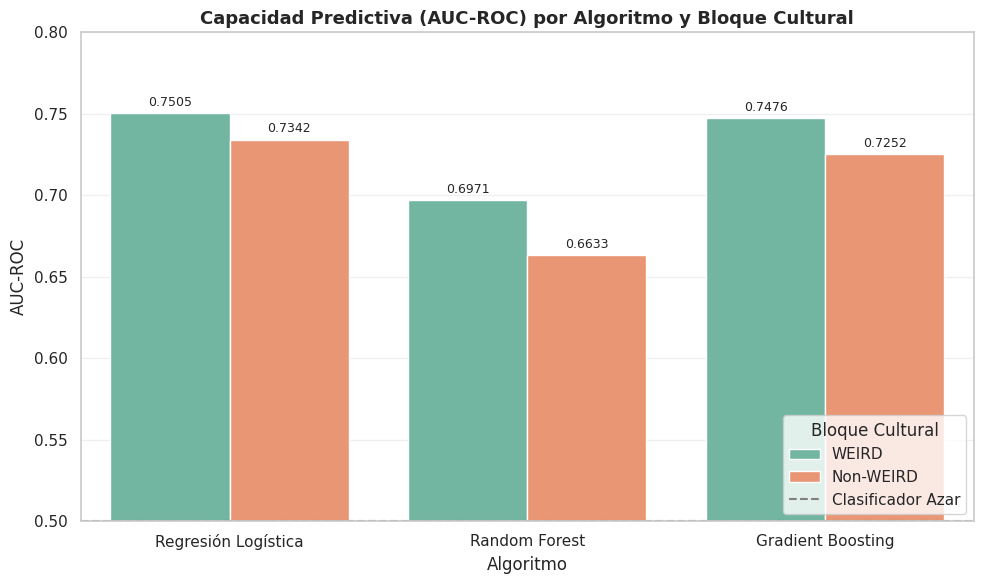

In [7]:
# Gráfico compartivo por bloque cultural: WEIRD vs NO-WEIRD

weird_countries = [2, 4, 5, 7, 10, 11, 12] # Alemania, Israel, Italia, Polonia, Suecia, UK, USA
df['is_weird'] = df['Country'].apply(lambda x: 1 if x in weird_countries else 0)

weird_results = []

for label, val in [("WEIRD", 1), ("Non-WEIRD", 0)]:
    subset = df[df['is_weird'] == val][features + ['indice_proteccion']].dropna()
    median_prot = subset['indice_proteccion'].median()

    y_sub = (subset['indice_proteccion'] > median_prot).astype(int)
    X_sub = subset[features]

    X_tr, X_te, y_tr, y_te = train_test_split(X_sub, y_sub, test_size=0.2, random_state=42)

    for name, clf_inst in [("Regresión Logística", LogisticRegression(max_iter=1000, random_state=42)),
                           ("Random Forest", RandomForestClassifier(n_estimators=100, random_state=42)),
                           ("Gradient Boosting", GradientBoostingClassifier(random_state=42))]:
        clf_inst.fit(X_tr, y_tr)
        y_prob_sub = clf_inst.predict_proba(X_te)[:, 1]
        auc_sub = roc_auc_score(y_te, y_prob_sub)

        weird_results.append({
            'Bloque Cultural': label,
            'Algoritmo': name,
            'AUC-ROC': auc_sub
        })

df_weird_res = pd.DataFrame(weird_results)

# Gráfico de barras agrupadas comparando los 3 algoritmos en ambos bloques
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_weird_res, x='Algoritmo', y='AUC-ROC', hue='Bloque Cultural', palette='Set2')
plt.title("Capacidad Predictiva (AUC-ROC) por Algoritmo y Bloque Cultural", fontsize=13, fontweight='bold')
plt.ylim(0.5, 0.8)
plt.axhline(0.5, color='gray', linestyle='--', label='Clasificador Azar')

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.legend(title='Bloque Cultural', loc='lower right')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Análisis de las gráficas según el análisis cultural

El ajuste de modelos independientes de Random Forest segmentados por bloque demográfico y cultural presenta diferencias significativas en el comportamiento predictivo, el bloque WEIRD (Alemania, Israel, Italia, Polonia, Reino Unido, EE. UU., etc.) obtuvo un *AUC-ROC* equivalente a $0,6971$, frente a un *AUC-ROC* de $0,6633$ del bloque NO-WEIRD.



# Conclusiones

* Existe una incompatibilidad de Modelos de Series Temporales en Datos Transversales, el dataset no contiene variables que puedan medir datos en formto tiempo y se descarta el uso del campo ID por ser un consecutivo y po rlo tanto se descarta el uso de ARIMA por lo tanto para evitar conclusiones sesgadas se hace uso de modelos de predicción como regresión logística, random forest y gradient boosting.

* La aplicación de lo modelos predictivos da como resutlado el predominio de lo cognitivo frente a lo sociodemográfico, es decir que el grado de conocimiento técnico se consdiera como la variable de predicción de mayor peso en la adopción de prácticas de protección digital y las variables sociodemográficas como la edad y educación tienen un papel secundario.

* Lo anterior implica una necesidad de implementar mayor educación en el área de la seguridad digital a todo nivel independiente de la edad o del nivel de formación de las personas.

* El modelo predictivo de regresión logística se considera el de mejor rendimiento para el análisis de ciberseguridad tomando como referncia el análisis de conocimiento frente a las variables demográficas que se hicieron en el estudio.

* Heterogeneidad Predictiva Sociocultural por lo que el comportamiento relacionado con la ciberseguridad puede varíar sustancialmente según el contexto estructural y cultural de la población analizada.